# Weekly Vulnerability Triage

Monday-morning triage workflow that combines two NVD data sources into
a single prioritized queue:

- **Recent feed** — CVEs published in the last ~8 days (new disclosures)
- **Modified feed** — CVEs changed recently (score revisions, new analysis, status updates)

Together these cover both net-new vulnerabilities and material changes to
existing ones. A composite risk score blends three signals — EPSS exploitation
probability, CVSS technical severity, and CISA KEV active-exploitation status —
into a single sortable priority for patch planning.

In [1]:
from vulnflow import VulnDataset
from vulnflow.helpers import CacheBuilder

# Pull both feeds — Recent (new disclosures) + Modified (changed CVEs)
recent = CacheBuilder(recent_only=True).build()
modified = CacheBuilder(modified_only=True).build()

# Merge with upsert semantics — if a CVE appears in both, Modified wins
ds = VulnDataset.merge([recent, modified])
df = ds.to_pandas()

print(f"{len(df):,} unique CVEs ({len(recent):,} recent + {len(modified):,} modified, deduplicated)")
print(f"Published range: {df['nvd_published_at'].min():%Y-%m-%d} .. {df['nvd_published_at'].max():%Y-%m-%d}")

Processing NVD feeds:   0%|          | 0/1 [00:00]

Enriching & transforming:   0%|          | 0/8 [00:00]

Processing NVD feeds:   0%|          | 0/1 [00:00]

Enriching & transforming:   0%|          | 0/8 [00:00]

16,490 unique CVEs (3,924 recent + 13,111 modified, deduplicated)
Published range: 2006-09-05 .. 2026-11-06


## Priority Tiers

Tiers are assigned by **exploitation status first, severity second**:

| Tier | Criteria | Action |
|------|----------|--------|
| **P0** | KEV (actively exploited) **or** EPSS ≥ 10% (high exploit probability) | Patch now |
| **P1** | CRITICAL severity, **or** HIGH + EPSS ≥ 1% | Patch this sprint |
| **P2** | HIGH severity, **or** MEDIUM + EPSS ≥ 1% | Schedule next cycle |
| **P3** | Everything else | Monitor |

The key insight: a MEDIUM-severity CVE with 15% EPSS is more urgent than
a CRITICAL with 0.01% EPSS. KEV and EPSS signal *operational* risk (it's
being exploited or will be soon); CVSS signals *theoretical* severity
(how bad it is if exploited). P0 captures both "it IS exploited" (KEV)
and "it WILL BE exploited" (high EPSS).

Within each tier, a **risk score** (0–100) provides sort order. The score
blends EPSS (40%), CVSS base score (30%), KEV status (20%), and the CVSS
exploitability subscore (10%) — the subscore captures attack-vector
accessibility (network vs local, no interaction, no privileges).

In [2]:
import numpy as np

# --- Composite risk score (for sort order within tiers) ---
epss = df["epss_probability"].fillna(0).clip(0, 1)
cvss = df["cvss_base_score"].fillna(0).clip(0, 10)
kev = df["is_kev"].fillna(False).astype(bool).astype(float)

# Exploitability bonus: 0-10 scaled from the CVSS exploitability subscore (0-3.9)
exploit_sub = df["cvss_exploitability_score"].fillna(0).clip(0, 3.9)
exploit_bonus = (exploit_sub / 3.9) * 10

df["risk_score"] = (
    epss * 40           # EPSS component (0-40)
    + (cvss / 10) * 30  # CVSS component (0-30)
    + kev * 20           # KEV component (0 or 20)
    + exploit_bonus      # Exploitability bonus (0-10)
).round(1)

# --- Priority tiers (exploitation status first, severity second) ---
severity = df["cvss_base_severity"].fillna("").str.upper()
is_kev = df["is_kev"].fillna(False).astype(bool)

p0 = is_kev | (epss >= 0.1)
p1 = (severity == "CRITICAL") | ((severity == "HIGH") & (epss >= 0.01))
p2 = (severity == "HIGH") | ((severity == "MEDIUM") & (epss >= 0.01))

df["priority"] = np.select([p0, p1, p2], ["P0", "P1", "P2"], default="P3")

tier_counts = df["priority"].value_counts().reindex(["P0", "P1", "P2", "P3"], fill_value=0)
for tier, count in tier_counts.items():
    print(f"  {tier}: {count:,} CVEs")

  P0: 81 CVEs
  P1: 1,724 CVEs
  P2: 5,958 CVEs
  P3: 8,727 CVEs


## Priority Queue

Top 25 CVEs by composite risk score. The `risk_score` column is the
weighted blend described above; `priority` maps it to an action tier.
KEV entries are always P0 regardless of their CVSS or EPSS values —
active exploitation overrides theoretical severity.

In [3]:
display_cols = [
    "priority", "risk_score", "cve_id",
    "epss_probability", "cvss_base_score", "cvss_base_severity",
    "is_kev", "cwe_name", "cpe_vendor",
]

(
    df.sort_values("risk_score", ascending=False)
    .head(25)
    [display_cols]
    .reset_index(drop=True)
)

,priority,risk_score,cve_id,epss_probability,cvss_base_score,cvss_base_severity,is_kev,cwe_name,cpe_vendor
0,P0,99.4,CVE-2026-109618,0.99999,9.8,CRITICAL,True,Use After Free,php
1,P0,97.0,CVE-2025-11953,0.9398,9.8,CRITICAL,True,Improper Neutralization of Special Elements us...,react-native-community
2,P0,93.2,CVE-2015-5477,0.99584,7.8,HIGH,True,NaN,juniper
3,P0,92.5,CVE-2026-111497,0.82641,9.8,CRITICAL,True,Unchecked Return Value,google
4,P0,92.4,CVE-2026-21589,0.99664,7.5,HIGH,True,Files or Directories Accessible to External Pa...,atlassian
5,P0,89.9,CVE-2026-109619,0.99999,8.1,HIGH,True,Use After Free,php
6,P0,88.7,CVE-2026-110447,0.73307,9.8,CRITICAL,True,Improper Neutralization of Special Elements us...,collabora
7,P0,86.1,CVE-2026-97229,0.6522,10.0,CRITICAL,True,Integer Overflow or Wraparound,gitlab
8,P0,78.4,CVE-2024-10914,0.97543,9.8,CRITICAL,False,Improper Neutralization of Special Elements in...,dlink
9,P0,77.2,CVE-2024-8517,0.94532,9.8,CRITICAL,False,External Control of File Name or Path,spip


## Risk Quadrant

CVSS measures *how bad* a vulnerability is; EPSS measures *how likely*
it is to be exploited. The quadrant helps separate theoretical severity
from operational urgency:

- **Upper-right** — high severity AND high exploit probability → top priority
- **Upper-left** — low severity but actively targeted → don't ignore
- **Lower-right** — severe but unlikely to be exploited soon → schedule
- **Lower-left** — low on both axes → monitor

Red dots are in the CISA KEV catalog (confirmed active exploitation).
Dashed lines at CVSS 7 and EPSS 0.1 mark common thresholds.

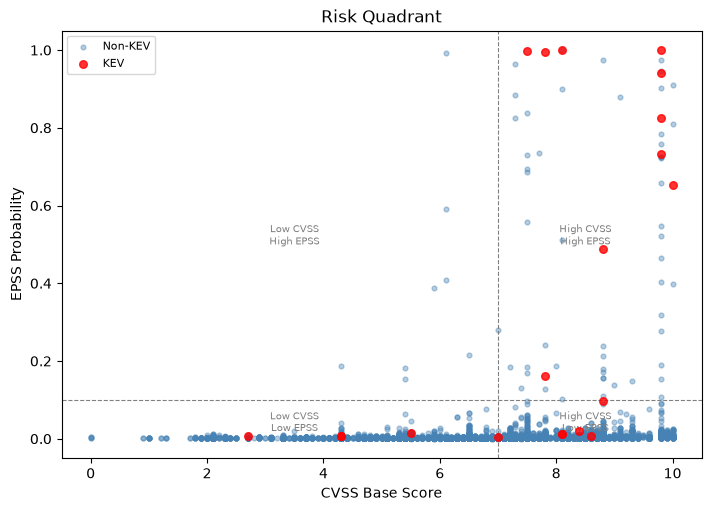

In [4]:
import matplotlib.pyplot as plt

plot_df = df.dropna(subset=["cvss_base_score", "epss_probability"])

fig, ax = plt.subplots(figsize=(7, 5), layout="constrained")

non_kev = plot_df[plot_df["is_kev"] != True]  # noqa: E712
kev_pts = plot_df[plot_df["is_kev"] == True]  # noqa: E712

ax.scatter(non_kev["cvss_base_score"], non_kev["epss_probability"],
           alpha=0.4, s=12, color="steelblue", label="Non-KEV")
ax.scatter(kev_pts["cvss_base_score"], kev_pts["epss_probability"],
           alpha=0.8, s=30, color="red", label="KEV", zorder=5)

ax.axvline(7, color="grey", linestyle="--", linewidth=0.8)
ax.axhline(0.1, color="grey", linestyle="--", linewidth=0.8)

ax.text(8.5, 0.02, "High CVSS\nLow EPSS", fontsize=7, color="grey", ha="center")
ax.text(8.5, 0.5, "High CVSS\nHigh EPSS", fontsize=7, color="grey", ha="center")
ax.text(3.5, 0.5, "Low CVSS\nHigh EPSS", fontsize=7, color="grey", ha="center")
ax.text(3.5, 0.02, "Low CVSS\nLow EPSS", fontsize=7, color="grey", ha="center")

ax.set_xlabel("CVSS Base Score")
ax.set_ylabel("EPSS Probability")
ax.set_title("Risk Quadrant")
ax.legend(fontsize=8)
plt.show()

## Score Breakdown

How the composite risk score distributes across priority tiers.
Most CVEs land in P2–P3 because few have active exploitation (KEV)
or high EPSS. The histogram shows score distribution; the bar chart
shows tier counts. Note that tiers are assigned by exploitation status
and severity thresholds, not by score cutoffs — the score only provides
sort order within each tier.

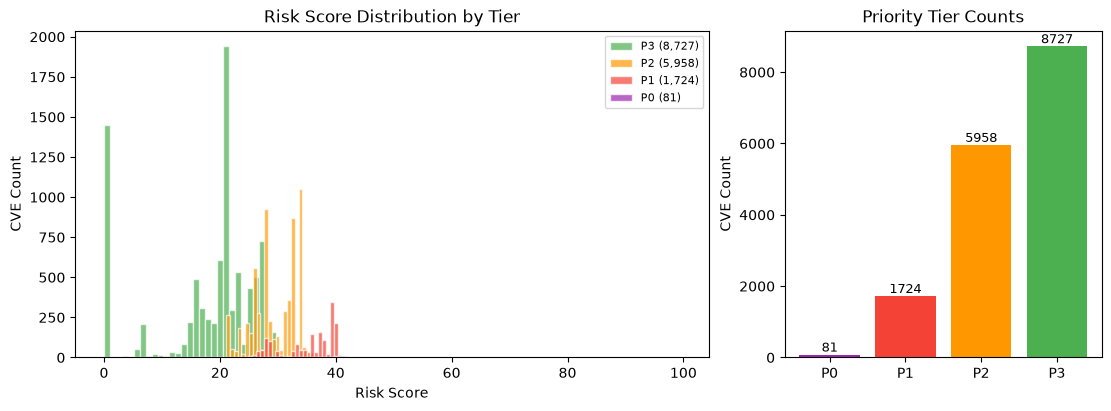

In [5]:
tier_colors = {"P0": "#9c27b0", "P1": "#f44336", "P2": "#ff9800", "P3": "#4caf50"}

fig, axes = plt.subplots(1, 2, figsize=(11, 4), gridspec_kw={"width_ratios": [2, 1]}, layout="constrained")

# Left: histogram of risk scores colored by tier
ax = axes[0]
for tier in ["P3", "P2", "P1", "P0"]:
    subset = df[df["priority"] == tier]["risk_score"]
    if len(subset) > 0:
        ax.hist(subset, bins=30, color=tier_colors[tier], alpha=0.7,
                label=f"{tier} ({len(subset):,})", edgecolor="white")
ax.set_xlabel("Risk Score")
ax.set_ylabel("CVE Count")
ax.set_title("Risk Score Distribution by Tier")
ax.legend(fontsize=8)

# Right: tier counts bar chart
ax2 = axes[1]
tiers = ["P0", "P1", "P2", "P3"]
counts = [tier_counts.get(t, 0) for t in tiers]
bars = ax2.bar(tiers, counts, color=[tier_colors[t] for t in tiers])
for bar, count in zip(bars, counts):
    if count > 0:
        ax2.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.5,
                 str(count), ha="center", va="bottom", fontsize=9)
ax2.set_title("Priority Tier Counts")
ax2.set_ylabel("CVE Count")

plt.show()

## Weakness Patterns in the Priority Queue

What *types* of vulnerabilities dominate the high-priority set?
Recurring CWE patterns may indicate systemic issues worth a broader
remediation effort (e.g., a wave of injection flaws across a vendor's
product line suggests a shared component).

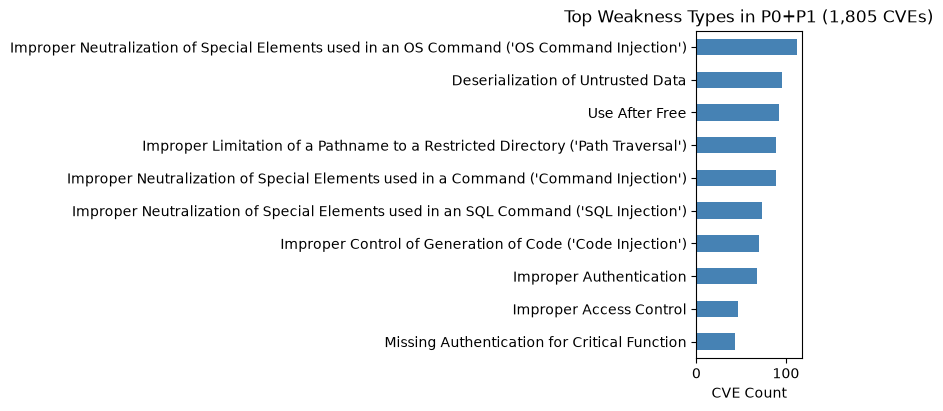

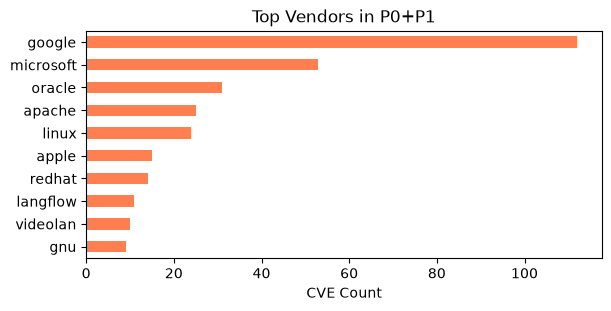

In [6]:
high_priority = df[df["priority"].isin(["P0", "P1"])]

if len(high_priority) > 0:
    # Top weakness types in P0+P1
    cwe_counts = (
        high_priority.dropna(subset=["cwe_name"])
        .loc[lambda d: d["cwe_id"] != "NVD-CWE-noinfo"]
        ["cwe_name"]
        .value_counts()
        .head(10)
    )

    fig, ax = plt.subplots(figsize=(8, 4), layout="constrained")
    cwe_counts.plot.barh(ax=ax, color="steelblue")
    ax.set_title(f"Top Weakness Types in P0+P1 ({len(high_priority):,} CVEs)")
    ax.set_xlabel("CVE Count")
    ax.set_ylabel("")
    ax.invert_yaxis()
    plt.show()

    # Top vendors in P0+P1
    vendor_counts = (
        high_priority.dropna(subset=["cpe_vendor"])
        ["cpe_vendor"]
        .value_counts()
        .head(10)
    )

    fig, ax = plt.subplots(figsize=(6, 3), layout="constrained")
    vendor_counts.plot.barh(ax=ax, color="coral")
    ax.set_title(f"Top Vendors in P0+P1")
    ax.set_xlabel("CVE Count")
    ax.set_ylabel("")
    ax.invert_yaxis()
    plt.show()
else:
    print("No P0 or P1 CVEs this week.")